In [1]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected")

    

PyTorch version: 2.14.1+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [3]:
import os
import random
import zipfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Keep CPU usage modest while other programs are open.
torch.set_num_threads(2)

# Use RTX 3050 automatically if CUDA is available.
device = 'cuda' if torch.cuda.is_available() else 'cpu'

print('Device:', device)

if device == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

    # Enable cuDNN benchmarking for faster CNN operations.
    torch.backends.cudnn.benchmark = True

else:
    print('GPU not available; training will use the CPU.')

# Set random seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [25]:

BATCH_SIZE = 32
LEARNING_RATE = 0.003
MINIMUM_LEARNING_RATE = 0.00001
EPOCHS = 30
DROPOUT = 0.1
USE_AUGMENTATION = True
MAX_IMAGES_PER_CLASS = 1000   # 500 x 19 = up to     images; None = full dataset

IMAGE_SIZE = 64             


In [26]:
DOWNLOADS = Path.home() / 'Downloads'
ZIP_PATH = DOWNLOADS / 'Combined Country - Updated.zip'
EXTRACT_DIR = DOWNLOADS / 'GeoSat19_Extracted'
DONE_FILE = EXTRACT_DIR / '.extracted'

# Also handle files renamed by the browser, such as "Combined Country - Updated (1).zip".
if not ZIP_PATH.is_file():
    matches = sorted(DOWNLOADS.glob('Combined Country - Updated*.zip'))
    if matches:
        ZIP_PATH = matches[0]

if not ZIP_PATH.is_file():
    raise FileNotFoundError(
        f'Cannot find Combined Country - Updated.zip in {DOWNLOADS}. '
        'If your Downloads folder is elsewhere, update DOWNLOADS above.'
    )

print('ZIP:', ZIP_PATH)
print('Extract folder:', EXTRACT_DIR)

if not DONE_FILE.is_file():
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    print('Extracting the dataset (first run only)...')
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)
    DONE_FILE.write_text('done', encoding='utf-8')
    print('Extraction completed!')
else:
    print('Already extracted — skipping unzip.')


ZIP: C:\Users\rahat\Downloads\Combined Country - Updated.zip
Extract folder: C:\Users\rahat\Downloads\GeoSat19_Extracted
Already extracted — skipping unzip.


In [28]:
import os
from collections import Counter

folder_counts = Counter()

for folder, subfolders, files in os.walk(EXTRACT_DIR):
    images = [
        f for f in files
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    if images:
        relative_folder = os.path.relpath(folder, EXTRACT_DIR)
        folder_counts[relative_folder] += len(images)

print("Total images found:", sum(folder_counts.values()))
print("\nFolders containing images:\n")

for folder, count in folder_counts.most_common(35):
    print(f"{folder}: {count} images")

print("\nTop-level extracted folders:")
print(os.listdir(EXTRACT_DIR)[:30])

Total images found: 74060

Folders containing images:

Combined Country - Updated\Agriculture: 11879 images
Combined Country - Updated\Forest: 11560 images
Combined Country - Updated\Overpass: 5052 images
Combined Country - Updated\River: 4939 images
Combined Country - Updated\ParkingLot: 4098 images
Combined Country - Updated\DenseResidential: 3719 images
Combined Country - Updated\GolfCourse: 3211 images
Combined Country - Updated\Intersection: 3206 images
Combined Country - Updated\Harbor: 3089 images
Combined Country - Updated\Chaparral: 2846 images
Combined Country - Updated\Quarry: 2678 images
Combined Country - Updated\MobileHomePark: 2634 images
Combined Country - Updated\TennisCourt: 2544 images
Combined Country - Updated\shurbland: 2269 images
Combined Country - Updated\Storagetanks: 2245 images
Combined Country - Updated\Railway: 2222 images
Combined Country - Updated\Runway: 2113 images
Combined Country - Updated\Freeway: 1907 images
Combined Country - Updated\MediumResiden

## 4. Read images and split the dataset

In [29]:
# The 19 published GeoSat-19 categories
CLASS_NAMES = [
    'Agriculture', 'Chaparral', 'Dense Residential', 'Forest', 'Freeway',
    'Golf Course', 'Harbor', 'Intersection', 'Medium Residential',
    'Mobile Home Park', 'Overpass', 'Parking Lot', 'Quarry', 'Railway',
    'River', 'Runway', 'Shrubland', 'Storage Tanks', 'Tennis Court'
]

# Match class folders, ignoring case, spaces, hyphens and underscores
def clean_name(name):
    return ''.join(c for c in name.lower() if c.isalnum())

name_to_label = {clean_name(name): i for i, name in enumerate(CLASS_NAMES)}
name_to_label['shurbland'] = name_to_label['shrubland']
images_by_class = [[] for _ in CLASS_NAMES]

for folder, subfolders, filenames in os.walk(EXTRACT_DIR):
    parts = os.path.relpath(folder, EXTRACT_DIR).split(os.sep)
    label = next((name_to_label[clean_name(p)] for p in reversed(parts)
                  if clean_name(p) in name_to_label), None)
    if label is None:
        continue
    for filename in filenames:
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            images_by_class[label].append((os.path.join(folder, filename), label))

counts = [len(items) for items in images_by_class]
print('Images found:', sum(counts))
for name, count in zip(CLASS_NAMES, counts):
    print(f'{name:22s} {count}')

if any(count < 10 for count in counts):
    raise ValueError('Some classes have too few images. Check the extracted folder names and ZIP contents.')

print("Number of classes:", len(CLASS_NAMES))

Images found: 74060
Agriculture            11879
Chaparral              2846
Dense Residential      3719
Forest                 11560
Freeway                1907
Golf Course            3211
Harbor                 3089
Intersection           3206
Medium Residential     1849
Mobile Home Park       2634
Overpass               5052
Parking Lot            4098
Quarry                 2678
Railway                2222
River                  4939
Runway                 2113
Shrubland              2269
Storage Tanks          2245
Tennis Court           2544
Number of classes: 19


In [30]:
# Split each class into training, validation, testing
train_samples, val_samples, test_samples = [], [], []
rng = random.Random(42)

for items in images_by_class:
    items = items.copy()
    rng.shuffle(items)
    if MAX_IMAGES_PER_CLASS is not None:
        items = items[:MAX_IMAGES_PER_CLASS]

    n = len(items)
    train_end = int(0.70 * n)
    val_end = int(0.85 * n)
    train_samples += items[:train_end]
    val_samples += items[train_end:val_end]
    test_samples += items[val_end:]


train_steps = [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))]
if USE_AUGMENTATION:
    train_steps += [
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)
    ]
train_steps += [transforms.ToTensor()]

train_transform = transforms.Compose(train_steps)
val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

class SatelliteDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as img:
            image = self.transform(img.convert('RGB'))
        return image, label

train_data = SatelliteDataset(train_samples, train_transform)
val_data = SatelliteDataset(val_samples, val_transform)
test_data = SatelliteDataset(test_samples, val_transform)

print(f'Train: {len(train_data)} | Validation: {len(val_data)} | Test: {len(test_data)}')

Train: 13300 | Validation: 2850 | Test: 2850


## 5. See sample images and create DataLoaders

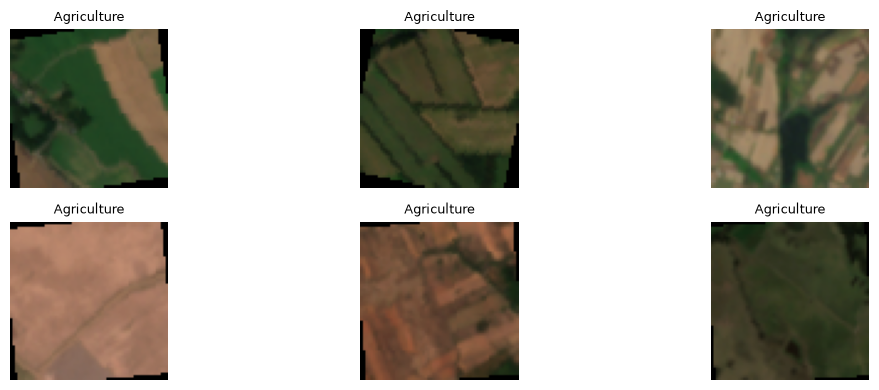

In [31]:
plt.figure(figsize=(12, 4))
for i in range(6):
    image, label = train_data[i]
    plt.subplot(2, 3, i + 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.title(CLASS_NAMES[label], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

## 6. Define the CNN model

In [32]:
class CNNModel(nn.Module):
    def __init__(self, num_classes=19):
        super().__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3,padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3,padding=1),
            nn.MaxPool2d(2),
            nn.ReLU()
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

from torchsummary import summary

model = CNNModel(num_classes=len(CLASS_NAMES)).to(device)

optimizer = Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=MINIMUM_LEARNING_RATE
)
criterion = nn.CrossEntropyLoss()

# Display the CNN architecture
summary(model, input_size=(3, IMAGE_SIZE, IMAGE_SIZE), device=device)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 64, 64]           1,792
         MaxPool2d-2           [-1, 64, 32, 32]               0
              ReLU-3           [-1, 64, 32, 32]               0
            Conv2d-4          [-1, 128, 30, 30]          73,856
         MaxPool2d-5          [-1, 128, 15, 15]               0
              ReLU-6          [-1, 128, 15, 15]               0
            Conv2d-7          [-1, 128, 15, 15]         147,584
         MaxPool2d-8            [-1, 128, 7, 7]               0
              ReLU-9            [-1, 128, 7, 7]               0
          Flatten-10                 [-1, 6272]               0
           Linear-11                  [-1, 256]       1,605,888
             ReLU-12                  [-1, 256]               0
          Dropout-13                  [-1, 256]               0
           Linear-14                   

## 7. Training and validation functions


In [33]:
def train_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


def validate_epoch(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

## 8. Train the CNN


In [34]:
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

best_val_acc = 0
BEST_MODEL_PATH = DOWNLOADS / 'geosat19_best_cnn.pth'

for epoch in range(EPOCHS):
    current_lr = optimizer.param_groups[0]['lr']
    train_loss, train_acc = train_epoch(model, train_loader)
    val_loss, val_acc = validate_epoch(model, val_loader)
    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    if val_acc >= best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)

    print(f'Epoch {epoch+1}/{EPOCHS} | LR {current_lr:.8f} | '
          f'Train loss {train_loss:.4f}, acc {train_acc:.2%} | '
          f'Val loss {val_loss:.4f}, acc {val_acc:.2%}')

print(f'Best validation accuracy: {best_val_acc:.2%}')

Epoch 1/30 | LR 0.00300000 | Train loss 2.7198, acc 13.59% | Val loss 2.5730, acc 19.02%
Epoch 2/30 | LR 0.00299181 | Train loss 2.5464, acc 20.59% | Val loss 2.5591, acc 18.84%
Epoch 3/30 | LR 0.00296733 | Train loss 2.4656, acc 23.08% | Val loss 2.4531, acc 22.81%
Epoch 4/30 | LR 0.00292683 | Train loss 2.4289, acc 24.29% | Val loss 2.3805, acc 24.81%
Epoch 5/30 | LR 0.00287075 | Train loss 2.3782, acc 25.72% | Val loss 2.3592, acc 24.46%
Epoch 6/30 | LR 0.00279971 | Train loss 2.3477, acc 26.20% | Val loss 2.3564, acc 25.96%
Epoch 7/30 | LR 0.00271448 | Train loss 2.3243, acc 27.07% | Val loss 2.3011, acc 26.84%
Epoch 8/30 | LR 0.00261600 | Train loss 2.3140, acc 27.44% | Val loss 2.3188, acc 26.18%
Epoch 9/30 | LR 0.00250535 | Train loss 2.2786, acc 28.33% | Val loss 2.2980, acc 26.81%
Epoch 10/30 | LR 0.00238374 | Train loss 2.2824, acc 27.74% | Val loss 2.2997, acc 27.40%
Epoch 11/30 | LR 0.00225250 | Train loss 2.2470, acc 28.65% | Val loss 2.2878, acc 27.93%
Epoch 12/30 | LR 0.

## 9. Plot training and validation accuracy/loss

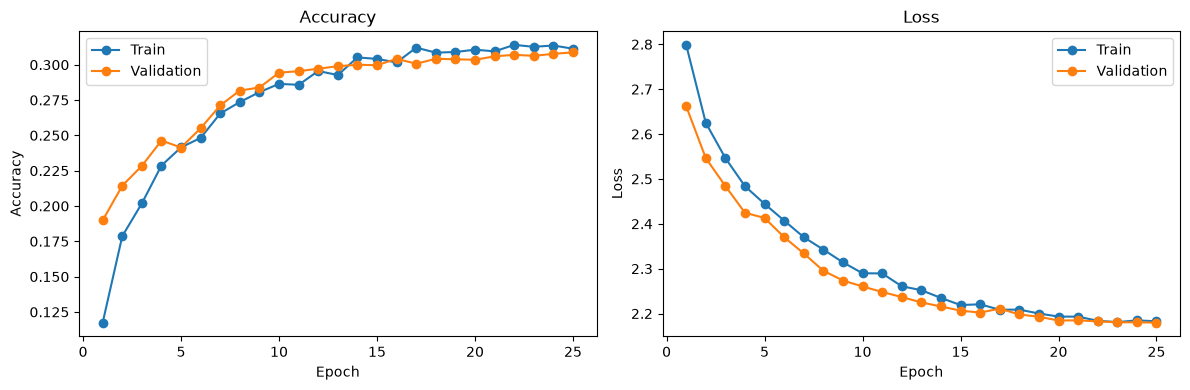

In [13]:
epoch_numbers = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, train_accuracies, marker='o', label='Train')
plt.plot(epoch_numbers, val_accuracies, marker='o', label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, train_losses, marker='o', label='Train')
plt.plot(epoch_numbers, val_losses, marker='o', label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Final test accuracy and confusion matrix

Test accuracy: 32.39%


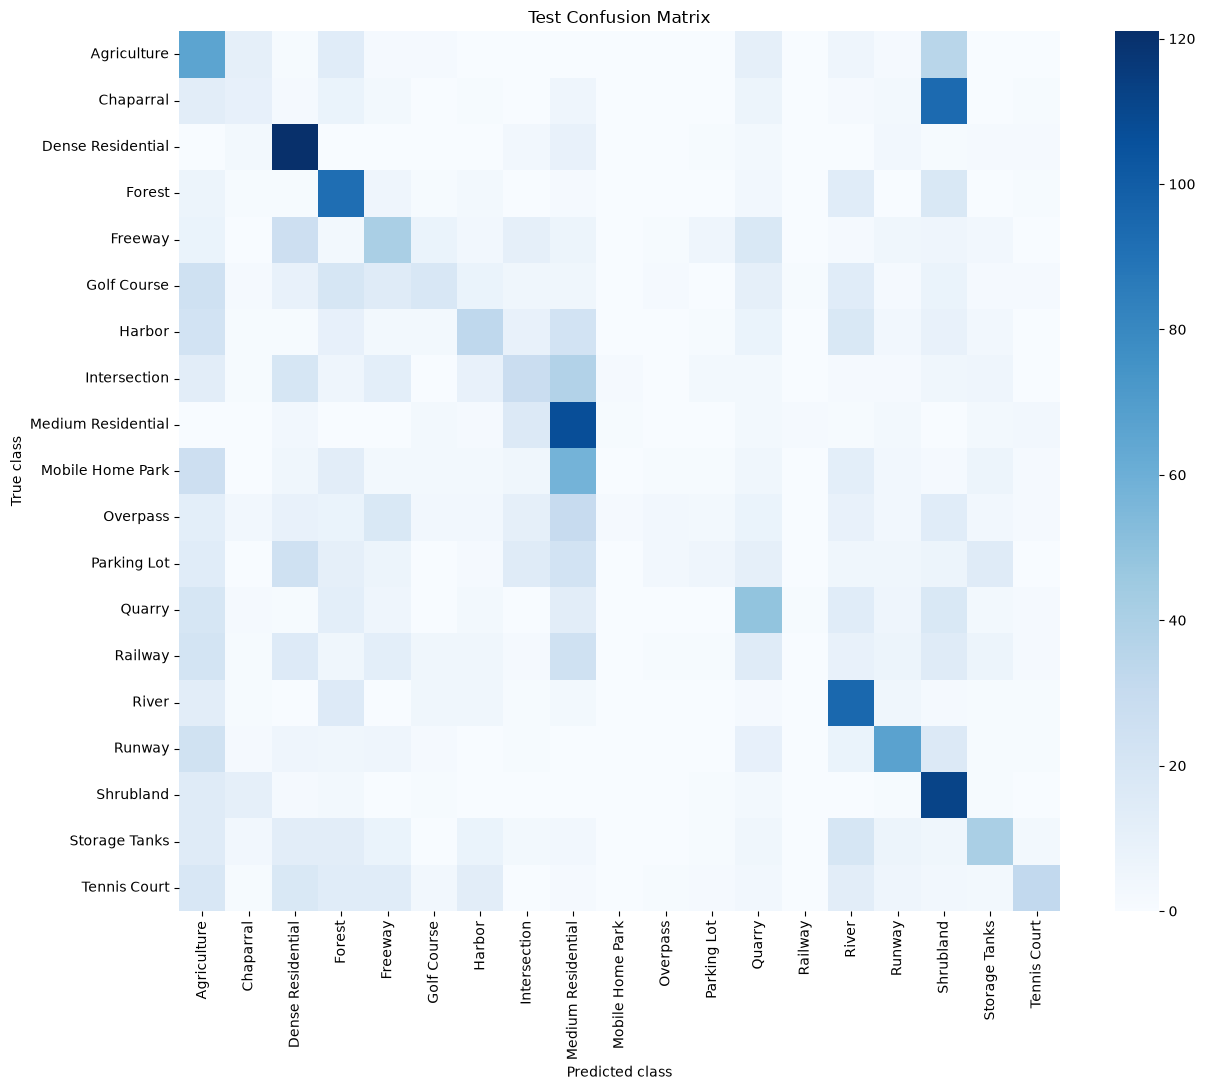

In [14]:
# Use the weights from the epoch with the best validation accuracy
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True))
model.eval()

all_labels, all_preds = [], []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        preds = outputs.argmax(1).cpu()
        all_labels.extend(labels.numpy())
        all_preds.extend(preds.numpy())

test_acc = np.mean(np.array(all_labels) == np.array(all_preds))
print(f'Test accuracy: {test_acc:.2%}')

cm = confusion_matrix(all_labels, all_preds, labels=range(len(CLASS_NAMES)))
plt.figure(figsize=(13, 11))
sns.heatmap(cm, cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title('Test Confusion Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Show predictions for 6 test images

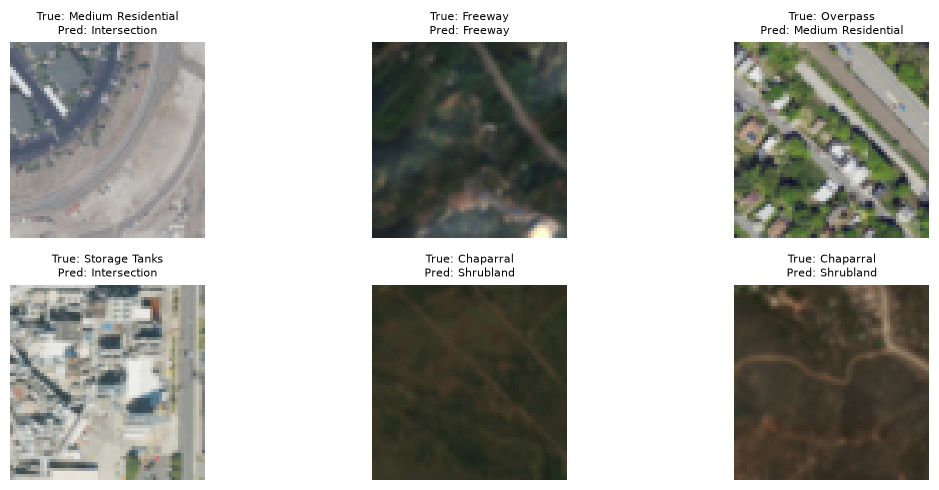

In [15]:
rng = random.Random(7)
selected = rng.sample(range(len(test_data)), min(6, len(test_data)))

plt.figure(figsize=(12, 5))
model.eval()
with torch.no_grad():
    for i, index in enumerate(selected):
        image, actual = test_data[index]
        output = model(image.unsqueeze(0).to(device))
        predicted = output.argmax(1).item()

        plt.subplot(2, 3, i + 1)
        plt.imshow(image.permute(1, 2, 0))
        plt.title(f'True: {CLASS_NAMES[actual]}\nPred: {CLASS_NAMES[predicted]}', fontsize=8)
        plt.axis('off')

plt.tight_layout()
plt.show()